# I will use transfer learning for for this project

first I will train a CNN from strach on ESC50 Data and then freeze the parameters and then will train on GENRES_STEMS Data

In [1]:
from helper.golbal_variables import *

## Exploring EC50 data

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import IPython.display as ipd

In [ ]:
esc50_df = pd.read_csv(ESC_50_MASTER/"meta/esc50.csv")

Files follow a specific pattern: {FOLD}-{CLIP_ID}-{TAKE}-{TARGET}.wav. The TARGET (0-49) is the class ID you are trying to predict.

In [ ]:
esc50_df.shape

In [ ]:
esc50_df.head()

In [ ]:
plt.figure(figsize=(16, 7))
sns.countplot(data=esc50_df, y="category")
plt.title("Distribution of each target")
plt.show()

All category have same distribution our data of ECS50 is balanced

## Checking wave forms

### Checking genres

In [ ]:
from pathlib import Path
import librosa
import librosa.display
import matplotlib.pyplot as plt
import IPython.display as ipd
from IPython.display import display

def plot_each_wav(folder: Path):
    files = list(folder.glob("*.wav")) 
    
    if not files:
        print(f"No .wav files found in {folder}")
        return

    fig, axes = plt.subplots(len(files), 1, figsize=(14, 3 * len(files)), squeeze=False)
    axes = axes.flatten()

    for ax, filename in zip(axes, files):
        data, sample_rate = librosa.load(filename, sr=None)
        librosa.display.waveshow(data, sr=sample_rate, ax=ax)
        
        ax.set_title(filename.name)
        ax.set_xlabel("Time (seconds)")
        ax.set_ylabel("Amplitude")

    plt.tight_layout()
    plt.show()

    print("\nAudio Samples:\n")
    for filename in files:
        print(filename.name)
        display(ipd.Audio(str(filename)))
        print("-" * 60)

### BLUES

In [ ]:
# plot_each_wav(BLUES / "blues.00000")

### classical

In [ ]:
# plot_each_wav(CLASSICAL / "classical.00000")

## 

# Now let's train a model on ESC50 dataset

In [2]:
import torch
from helper.DataLoaders.dataloader_with_preprocessed import GenreDataLoader, collate_fn_chunks, ESC50_DataLoader
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import librosa.display
from IPython.display import display
import IPython.display as ipd

### Checking if DataLoader is laoding data properly

In [ ]:
# dataset = ESC50_DataLoader(ESC_50_MASTER)
# dataset.load_meta_data(ESC_50_MASTER/"meta/esc50.csv")

# loader = DataLoader(dataset, batch_size=16, shuffle=True)2

# for x, y in loader:
#     print(x.shape)
#     print(y.shape)
#     break

Checking if loader if giving correct spectrum

### Now let's train our model on ESC50 dataset

In [ ]:
from collections import Counter
from torch.utils.data import DataLoader

# Load your training dataset
dataset = GenreDataLoader(root_dir=GENRES_STEMS)

# Count samples per genre
genre_counts = Counter(dataset.labels)
genre_names = {v: k for k, v in dataset.class_map.items()}

print("Current Distribution:")
for genre_idx, count in sorted(genre_counts.items()):
    genre_name = genre_names[genre_idx]
    print(f"  {genre_name}: {count} songs")

print(f"\nTotal: {len(dataset)} songs")
print(f"Min: {min(genre_counts.values())}, Max: {max(genre_counts.values())}")
print(f"Imbalance ratio: {max(genre_counts.values()) / min(genre_counts.values()):.2f}x")

In [4]:
dataloader = DataLoader(
    dataset=dataset,
    shuffle=False,
    collate_fn=collate_fn_chunks,
    batch_size=16
)

In [5]:
for all_chunks, labels, chunk_counts in dataloader:
    print(all_chunks.shape)
    print(labels.shape)
    print(len(chunk_counts))
    break

torch.Size([96, 1, 128, 431])
torch.Size([96])
16


Classes: {'blues': 0, 'classical': 1, 'country': 2, 'disco': 3, 'hiphop': 4, 'jazz': 5, 'metal': 6, 'pop': 7, 'reggae': 8, 'rock': 9}
Total songs: 1000
Current Distribution:
  blues: 100 songs
  classical: 100 songs
  country: 100 songs
  disco: 100 songs
  hiphop: 100 songs
  jazz: 100 songs
  metal: 100 songs
  pop: 100 songs
  reggae: 100 songs
  rock: 100 songs

Total: 1000 songs
Min: 100, Max: 100
Imbalance ratio: 1.00x
Sample index       : 12
Genre label        : 0 (blues)
Number of chunks   : 6
Chunk tensor shape : torch.Size([6, 1, 128, 431])
First chunk shape  : torch.Size([1, 128, 431])
Sample rate        : 22050 Hz
Chunk duration     : 5s

  CHUNK 1 / 6  —  0s → 5s
  Shape after conversion: (128, 431)
  Norm range: [-52.83, 27.17]


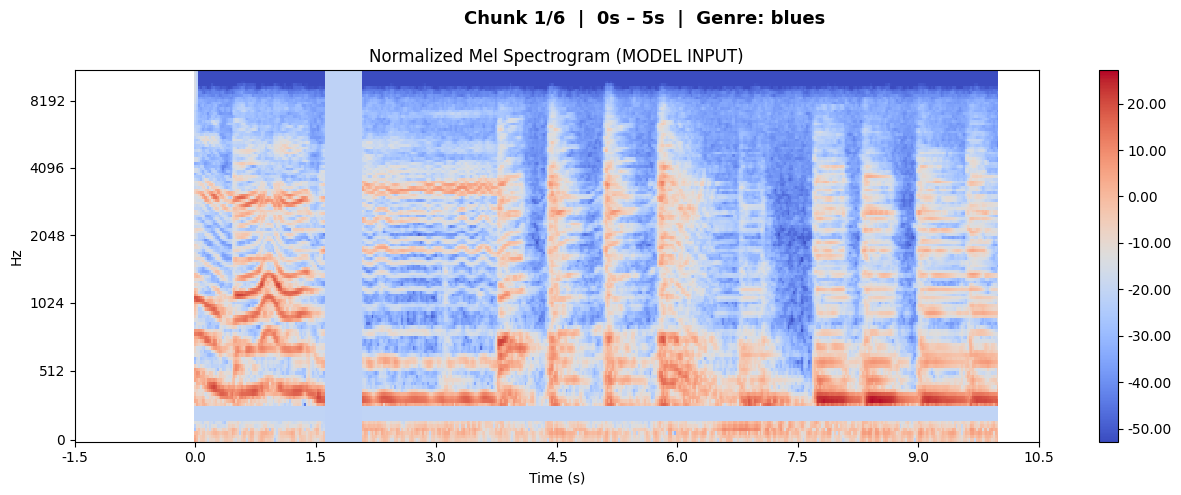


  CHUNK 2 / 6  —  5s → 10s
  Shape after conversion: (128, 431)
  Norm range: [-53.07, 26.93]


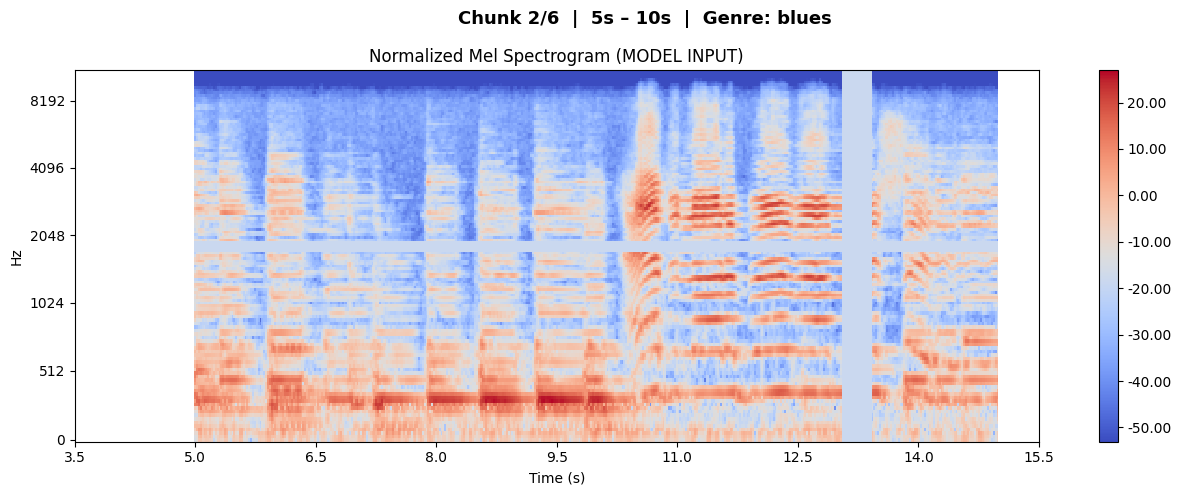


  CHUNK 3 / 6  —  10s → 15s
  Shape after conversion: (128, 431)
  Norm range: [-51.60, 28.40]


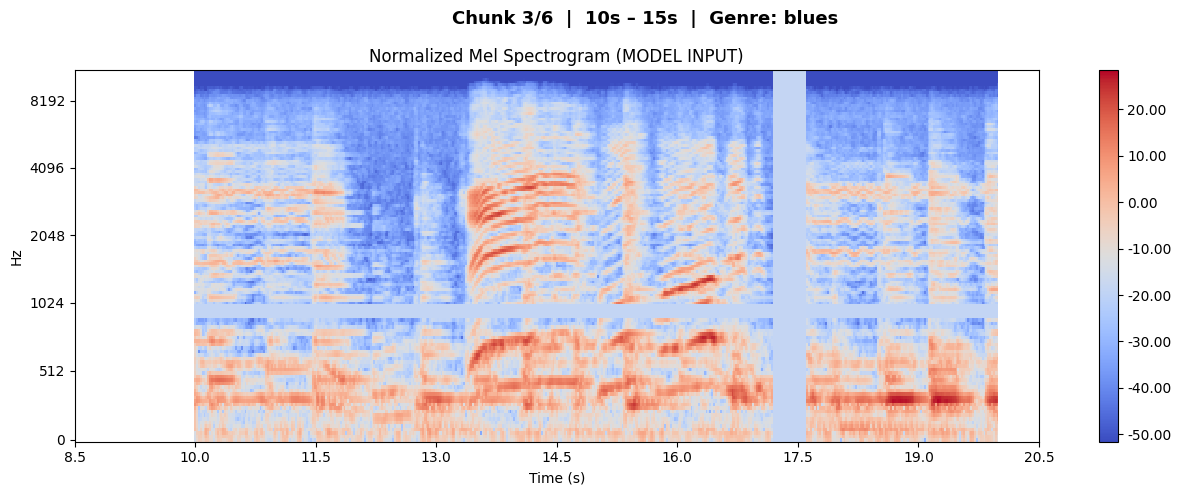


  CHUNK 4 / 6  —  15s → 20s
  Shape after conversion: (128, 431)
  Norm range: [-52.30, 27.54]


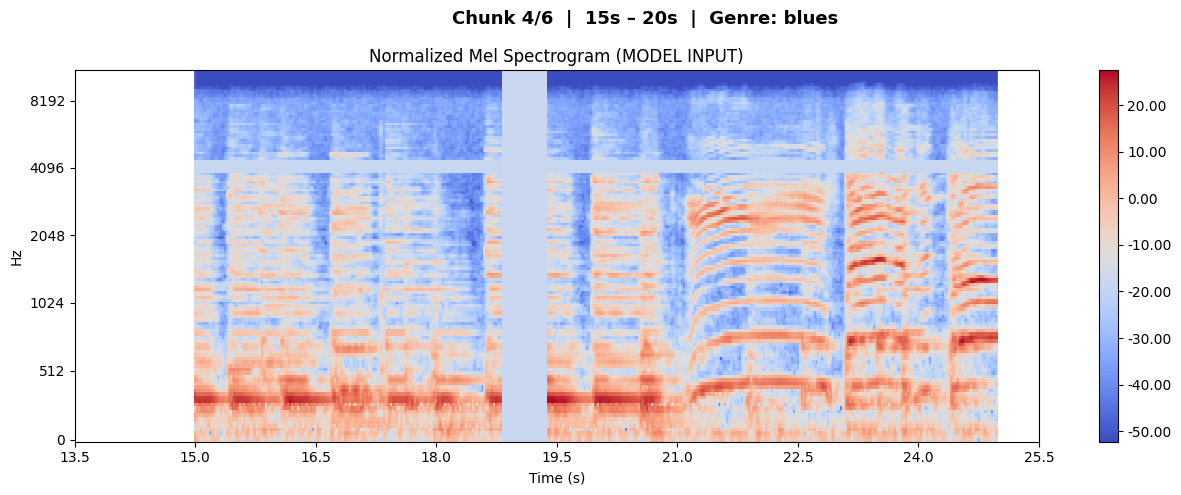


  CHUNK 5 / 6  —  20s → 25s
  Shape after conversion: (128, 431)
  Norm range: [-51.33, 28.67]


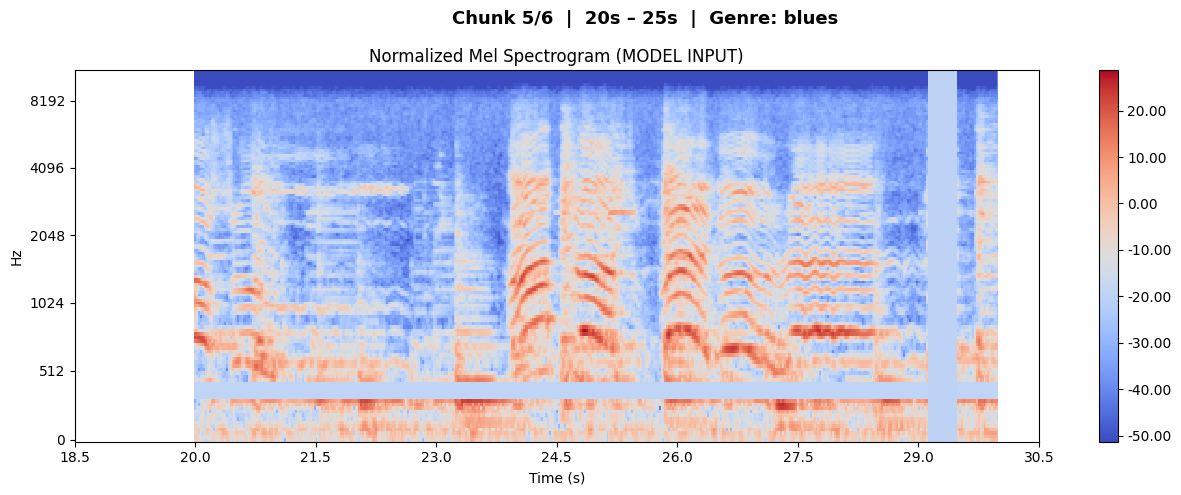


  CHUNK 6 / 6  —  25s → 30s
  Shape after conversion: (128, 431)
  Norm range: [-53.63, 26.37]


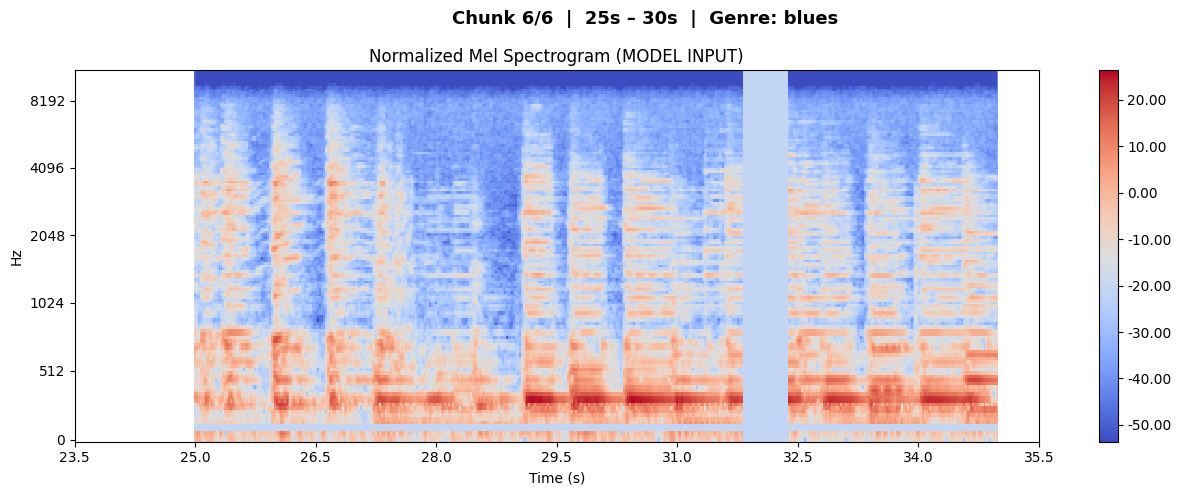

In [1]:
from helper.golbal_variables import *

import torch
from helper.DataLoaders.dataloader_with_preprocessed import GenreDataLoader, collate_fn_chunks, ESC50_DataLoader


from collections import Counter
from torch.utils.data import DataLoader

# Load your training dataset
dataset = GenreDataLoader(root_dir=GENRES_STEMS, augment=True)

# Count samples per genre
genre_counts = Counter(dataset.labels)
genre_names = {v: k for k, v in dataset.class_map.items()}

print("Current Distribution:")
for genre_idx, count in sorted(genre_counts.items()):
    genre_name = genre_names[genre_idx]
    print(f"  {genre_name}: {count} songs")

print(f"\nTotal: {len(dataset)} songs")
print(f"Min: {min(genre_counts.values())}, Max: {max(genre_counts.values())}")
print(f"Imbalance ratio: {max(genre_counts.values()) / min(genre_counts.values()):.2f}x")


dataloader = DataLoader(
    dataset=dataset,
    shuffle=False,
    collate_fn=collate_fn_chunks,
    batch_size=16
)


import matplotlib.pyplot as plt
import librosa.display
import torch
import numpy as np

# ✅ Get one sample directly from your dataloader
idx = 12

# Load the sample through dataloader (already preprocessed)
chunks, label = dataset[idx]

num_chunks = chunks.shape[0]
variables = dataset.variables

# ✅ Create inverse mapping from class_map
class_map_inverse = {v: k for k, v in dataset.class_map.items()}

print(f"Sample index       : {idx}")
print(f"Genre label        : {label} ({class_map_inverse[label.item()]})")
print(f"Number of chunks   : {num_chunks}")
print(f"Chunk tensor shape : {chunks.shape}")
print(f"First chunk shape  : {chunks[0].shape}")
print(f"Sample rate        : {variables.SAMPLE_RATE} Hz")
print(f"Chunk duration     : {variables.SAMPLES / variables.SAMPLE_RATE:.0f}s")


def specshow_with_offset(ax, mel_np, sr, hop_length, chunk_start_sec, chunk_end_sec):
    """Draw spectrogram with shifted time axis."""
    img = librosa.display.specshow(
        mel_np,
        sr=sr,
        hop_length=512,
        x_axis="time",
        y_axis="mel",
        ax=ax,
    )
    # Shift x-axis to reflect real song time
    ticks = ax.get_xticks()
    shifted_ticks = [t + chunk_start_sec for t in ticks]
    ax.set_xticks(ticks)
    ax.set_xticklabels([f"{t:.1f}" for t in shifted_ticks])
    ax.set_xlabel("Time (s)")
    return img


# =========================
# PER-CHUNK PLOTS
# =========================
for i in range(num_chunks):
    chunk = chunks[i]  # Could be (1, 128, T) or (128, T)
    
    chunk_start_sec = i * 5
    chunk_end_sec = (i + 1) * 5

    # ✅ Handle both (1, 128, T) and (128, T) shapes
    if chunk.ndim == 3:  # (1, 128, T)
        mel_np_norm = chunk.squeeze(0).detach().cpu().numpy()  # → (128, T)
    elif chunk.ndim == 2:  # (128, T)
        mel_np_norm = chunk.detach().cpu().numpy()
    else:  # (T,) - 1D, something is wrong
        print(f"⚠ Chunk {i+1} has unexpected shape: {chunk.shape}")
        continue

    print(f"\n{'='*55}")
    print(f"  CHUNK {i+1} / {num_chunks}  —  {chunk_start_sec:.0f}s → {chunk_end_sec:.0f}s")
    print(f"{'='*55}")
    print(f"  Shape after conversion: {mel_np_norm.shape}")  # Must be (128, T)
    print(f"  Norm range: [{mel_np_norm.min():.2f}, {mel_np_norm.max():.2f}]")
    
    # ✅ Verify it's 2D
    if mel_np_norm.ndim != 2:
        print(f"  ⚠ ERROR: Array is {mel_np_norm.ndim}D, expected 2D. Skipping...")
        continue

    fig, ax = plt.subplots(1, 1, figsize=(13, 5))
    fig.suptitle(
        f"Chunk {i+1}/{num_chunks}  |  {chunk_start_sec:.0f}s – {chunk_end_sec:.0f}s  "
        f"|  Genre: {class_map_inverse[label.item()]}",
        fontsize=13, fontweight="bold"
    )

    img = specshow_with_offset(
        ax, mel_np_norm,
        sr=variables.SAMPLE_RATE, 
        hop_length=512,
        chunk_start_sec=chunk_start_sec, 
        chunk_end_sec=chunk_end_sec
    )
    ax.set_title("Normalized Mel Spectrogram (MODEL INPUT)")
    fig.colorbar(img, ax=ax, format="%.2f")

    plt.tight_layout()
    plt.show()

# dfs

Loading metadata from file: z:\dlgen-AI-project\data\ESC-50-master\meta\esc50.csv


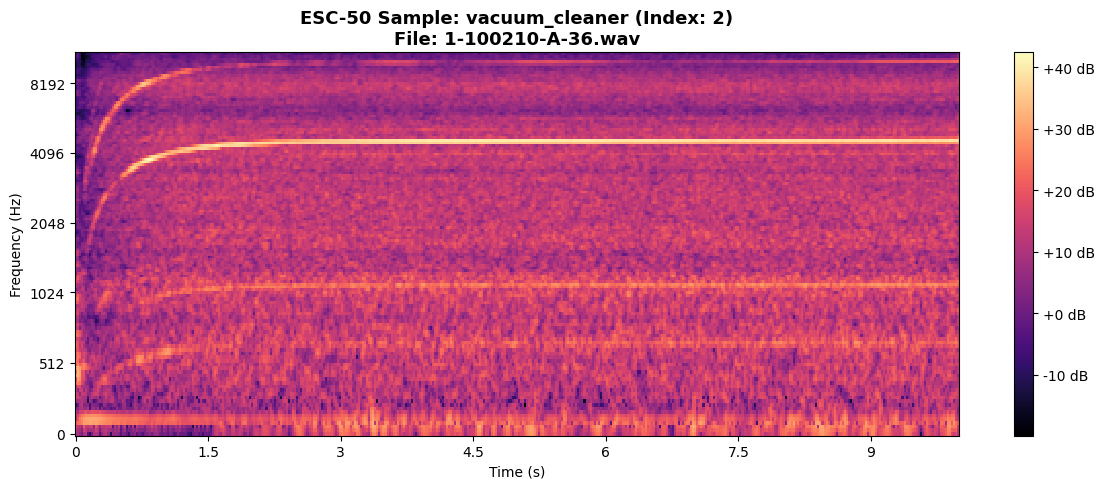

In [4]:
import matplotlib.pyplot as plt
import librosa.display
import torch

def visualize_esc50_sample(dataset, index=0):
    """
    Retrieves a sample from ESC50_DataLoader and plots its Mel Spectrogram.
    """
    # 1. Get the data from the dataset
    # This triggers your __getitem__ logic (filtering, resampling, mel-conversion)
    mel_spec, label = dataset[index]
    
    # 2. Extract metadata for the title
    row = dataset.meta_data.iloc[index]
    category = row["category"]
    filename = row["filename"]
    
    # 3. Prepare the tensor for plotting
    # mel_spec shape is likely (1, n_mels, time) -> needs to be (n_mels, time)
    mel_np = mel_spec.squeeze(0).cpu().numpy()
    
    # 4. Create the plot
    plt.figure(figsize=(12, 5))
    
    img = librosa.display.specshow(
        mel_np,
        sr=dataset.variables.SAMPLE_RATE,
        hop_length=512,  # Match this to your Variables() config if different
        x_axis="time",
        y_axis="mel",
        cmap="magma"
    )
    
    plt.colorbar(img, format="%+2.0f dB")
    plt.title(f"ESC-50 Sample: {category} (Index: {index})\nFile: {filename}", fontsize=13, fontweight='bold')
    plt.xlabel("Time (s)")
    plt.ylabel("Frequency (Hz)")
    plt.tight_layout()
    plt.show()

# --- Usage ---
esc_dataset = ESC50_DataLoader(ESC_50_MASTER)
esc_dataset.load_meta_data(ESC_50_MASTER/"meta/esc50.csv")

# loader = DataLoader(dataset, batch_size=16, shuffle=True)

# for x, y in loader:
#     print(x.shape)
#     print(y.shape)
#     break

visualize_esc50_sample(esc_dataset, index=2)